<a href="https://colab.research.google.com/github/wahiwatkar06-gif/student-placement-predictor/blob/main/Weather_predictor_ML_project_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

### Reading the Dataset

* date : dates
* precipitation : All forms in which water falls on the land surface and open water bodies as rain, sleet, snow, hail, or drizzle
* temp_max : Maximum Temperature
* temp_min : Minimum Temperature
* wind : Wind speed
* weather : weathers types

In [2]:
#Load the dataset
data = pd.read_csv("weather.csv")

In [3]:
data.head()

,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


In [4]:
data.tail()

,date,precipitation,temp_max,temp_min,wind,weather
1456,2015-12-27,8.6,4.4,1.7,2.9,rain
1457,2015-12-28,1.5,5.0,1.7,1.3,rain
1458,2015-12-29,0.0,7.2,0.6,2.6,fog
1459,2015-12-30,0.0,5.6,-1.0,3.4,sun
1460,2015-12-31,0.0,5.6,-2.1,3.5,sun


### Exploratory Data Analysis

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           1461 non-null   object 
 1   precipitation  1461 non-null   float64
 2   temp_max       1461 non-null   float64
 3   temp_min       1461 non-null   float64
 4   wind           1461 non-null   float64
 5   weather        1461 non-null   object 
dtypes: float64(4), object(2)
memory usage: 68.6+ KB


In [6]:
#Check for null values
data.isnull().sum()

,0
date,0
precipitation,0
temp_max,0
temp_min,0
wind,0
weather,0


In [7]:
#convert the data type into datetime
data['date'] = pd.to_datetime(data['date'])

In [8]:
data.columns

Index(['date', 'precipitation', 'temp_max', 'temp_min', 'wind', 'weather'], dtype='object')

In [9]:
data.nunique()

,0
date,1461
precipitation,111
temp_max,67
temp_min,55
wind,79
weather,5


### Data Visualization

In [10]:
data['weather'].value_counts()

,count
weather,
rain,641
sun,640
fog,101
drizzle,53
snow,26


/tmp/ipykernel_3332/758220560.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x = 'weather',data = data,palette="ch:start=.2,rot=-.3")


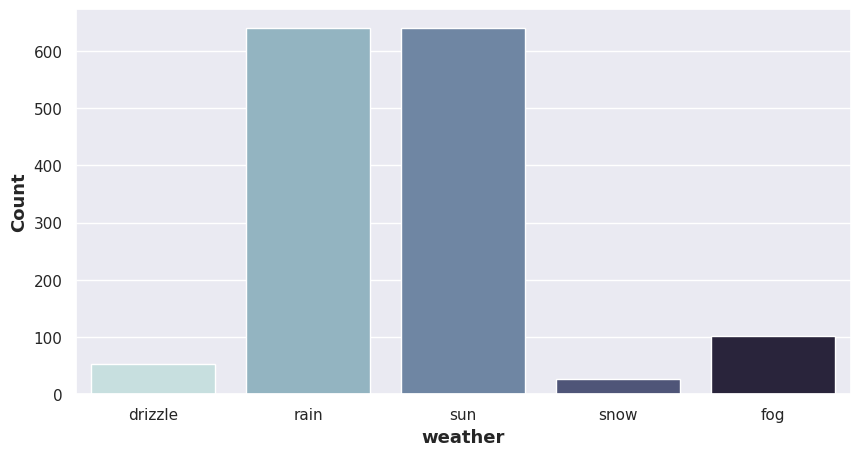

In [11]:
plt.figure(figsize=(10,5))
sns.set_theme()
sns.countplot(x = 'weather',data = data,palette="ch:start=.2,rot=-.3")
plt.xlabel("weather",fontweight='bold',size=13)
plt.ylabel("Count",fontweight='bold',size=13)
plt.show()

In [12]:
import plotly.express as px

In [13]:
px.line(data_frame = data,
       x = 'date',
       y = 'temp_max',
       title = 'Variation of Maximum Temperature')

In [14]:
px.line(data_frame = data,
       x = 'date',
       y = 'temp_min',
       title = 'Variation of Minimum Temperature')

In [15]:
px.line(data_frame = data,
       x = 'date',
       y = 'wind',
       title = 'Variation of Wind on different dates')

<Figure size 1400x800 with 0 Axes>

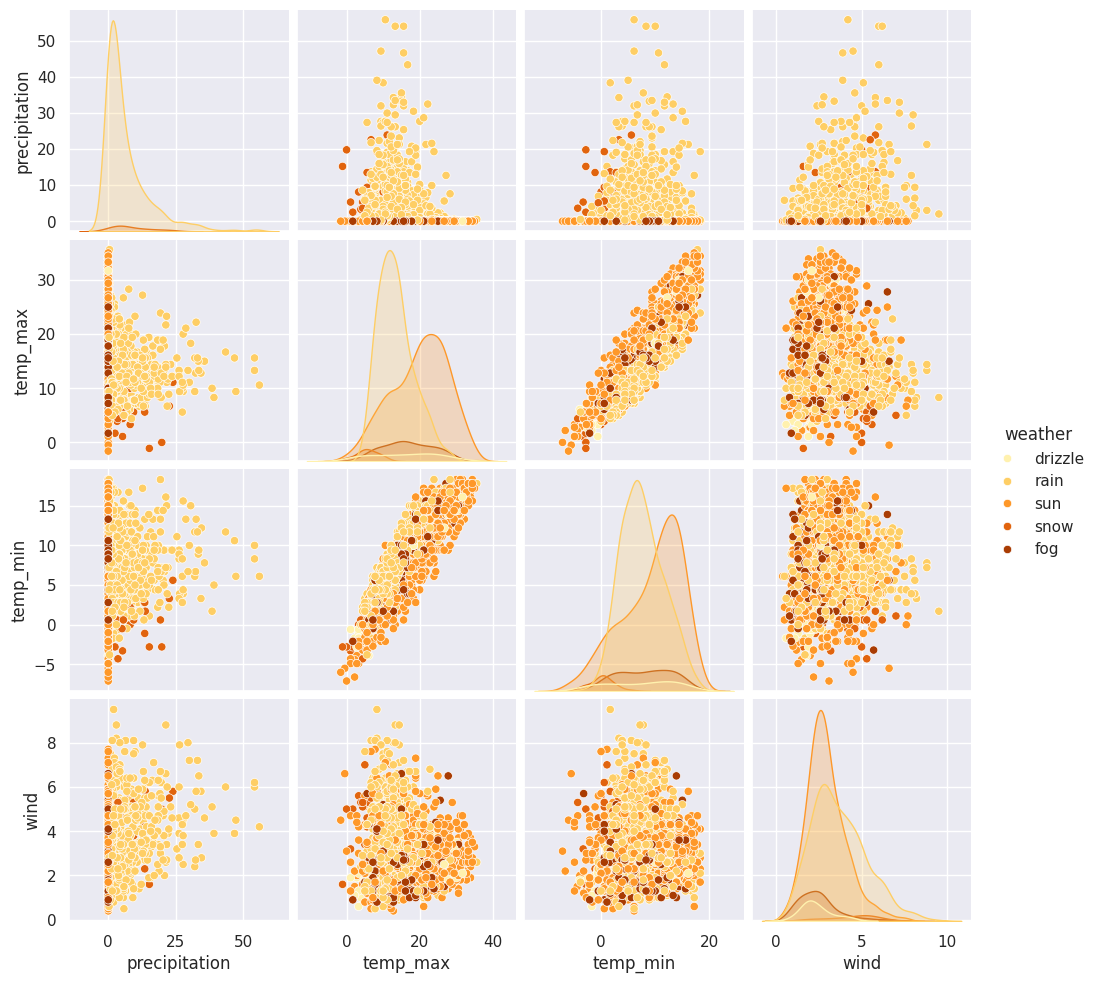

In [16]:
plt.figure(figsize=(14,8))
sns.pairplot(data.drop('date',axis=1),hue='weather',palette="YlOrBr")
plt.show()

/tmp/ipykernel_3332/3814060822.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




<Figure size 1000x500 with 0 Axes>

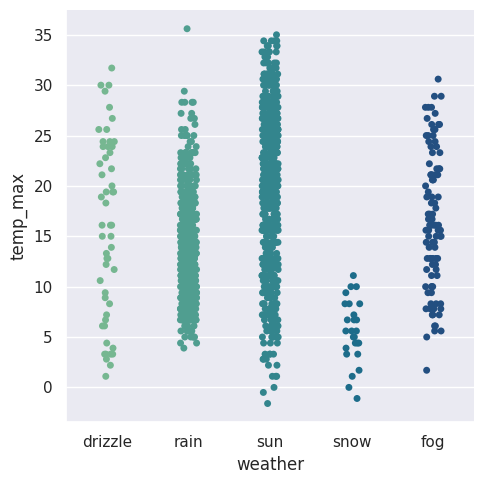

In [17]:
plt.figure(figsize=(10,5))
sns.catplot(x='weather',y ='temp_max',data=data,palette="crest")
plt.show()

/tmp/ipykernel_3332/1093999663.py:2: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.




<Figure size 1000x500 with 0 Axes>

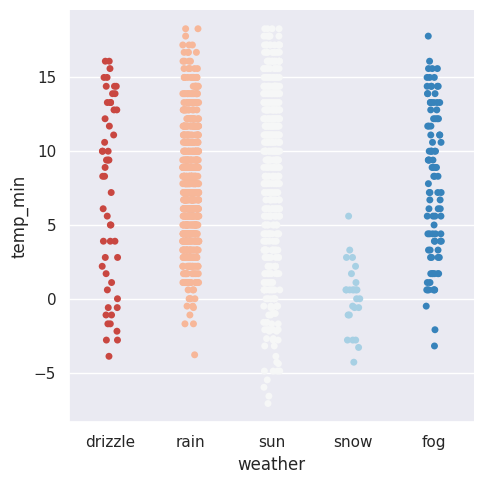

In [18]:
plt.figure(figsize=(10,5))
sns.catplot(x='weather',y ='temp_min',data=data,palette = "RdBu")
plt.show()

### Data Preprocessing

In [19]:
def LABEL_ENCODING(c1):
    from sklearn import preprocessing
    label_encoder = preprocessing.LabelEncoder()
    data[c1]= label_encoder.fit_transform(data[c1])
    data[c1].unique()
LABEL_ENCODING("weather")

In [20]:
data = data.drop('date',axis=1)

In [21]:
x = data.drop('weather',axis=1)
y = data['weather']

### Train Test Split

In [22]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.25, random_state = 0)

In [23]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Logistic Regression

In [24]:
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression(random_state = 0)
classifier.fit(X_train, y_train)

LogisticRegression(random_state=0)

In [25]:
y_pred = classifier.predict(X_test)

In [26]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(y_test, y_pred)

Accuracy score: 0.7622950819672131


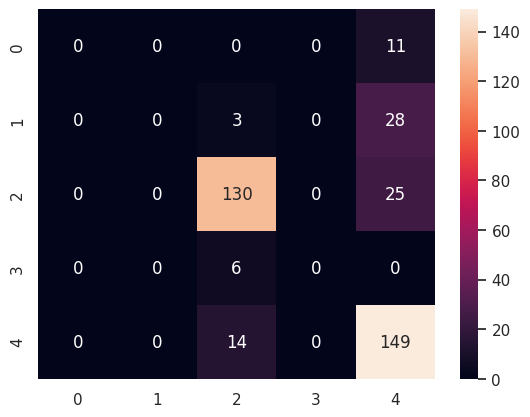

In [27]:
sns.heatmap(cm,annot=True, fmt = '.3g')
acc1 = accuracy_score(y_test, y_pred)
print(f"Accuracy score: {acc1}")
plt.show()

### SVM

In [28]:
from sklearn.svm import SVC
classifier = SVC(kernel = 'linear', random_state = 0)
classifier.fit(X_train, y_train)

SVC(kernel='linear', random_state=0)

### Predictions

In [29]:
y_pred = classifier.predict(X_test)

Accuracy Score 0.7950819672131147


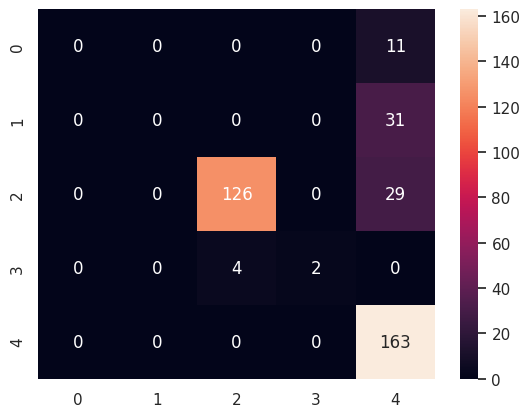

In [30]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot = True, fmt = '0.3g')
print("Accuracy Score" ,accuracy_score(y_test, y_pred))

### Naive Bayes

In [31]:
from sklearn.naive_bayes import GaussianNB
classifier = GaussianNB()
classifier.fit(X_train, y_train)

GaussianNB()

In [32]:
y_pred = classifier.predict(X_test)

Accuracy score : 0.8415300546448088


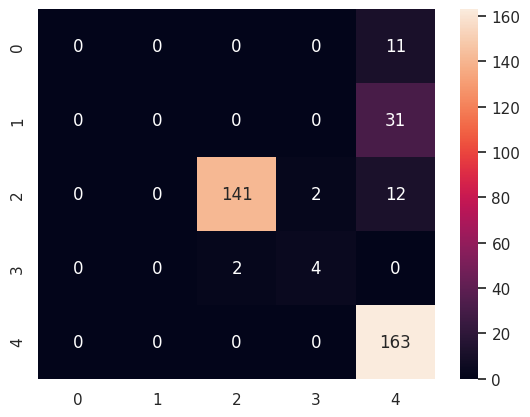

In [33]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot = True, fmt = '.3g')
acc = accuracy_score(y_test, y_pred)
print(f"Accuracy score : {acc}")

In [34]:
# Weather Prediction web interface (run after uploading weather.csv)
%pip -q install gradio

import pandas as pd
import gradio as gr
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

# Load the original, unencoded dataset so weather labels remain readable.
weather_df = pd.read_csv("weather.csv")
feature_cols = ["precipitation", "temp_max", "temp_min", "wind"]
required_cols = feature_cols + ["weather"]
missing_cols = [c for c in required_cols if c not in weather_df.columns]
if missing_cols:
    raise ValueError(f"weather.csv is missing required columns: {missing_cols}")
weather_df = weather_df[required_cols].dropna().copy()
X = weather_df[feature_cols]
y_text = weather_df["weather"].astype(str)
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)
X_train_app, X_test_app, y_train_app, y_test_app = train_test_split(
    X, y, test_size=0.25, random_state=0, stratify=y if pd.Series(y).value_counts().min() >= 2 else None
)

models = {
    "Logistic Regression": LogisticRegression(random_state=0, max_iter=1000),
    "SVM (Linear)": SVC(kernel="linear", random_state=0),
    "Naive Bayes": GaussianNB(),
}
trained_models = {}
model_accuracies = {}
for model_name, estimator in models.items():
    pipeline = Pipeline([("scaler", StandardScaler()), ("model", estimator)])
    pipeline.fit(X_train_app, y_train_app)
    trained_models[model_name] = pipeline
    model_accuracies[model_name] = accuracy_score(y_test_app, pipeline.predict(X_test_app))

print("Models trained successfully.")
for model_name, score in model_accuracies.items():
    print(f"{model_name}: {score:.2%} test accuracy")

def predict_weather(model_name, precipitation, temp_max, temp_min, wind):
    try:
        values = pd.DataFrame([[precipitation, temp_max, temp_min, wind]], columns=feature_cols)
        predicted_code = int(trained_models[model_name].predict(values)[0])
        predicted_label = label_encoder.inverse_transform([predicted_code])[0]
        return f"Predicted weather: {predicted_label}", f"{model_name} test accuracy: {model_accuracies[model_name]:.2%}"
    except Exception as exc:
        return f"Prediction error: {exc}", "Please check the input values and dataset."

with gr.Blocks(title="Weather Prediction") as weather_app:
    gr.Markdown("# 🌦️ Weather Prediction\nEnter the weather measurements below to test your trained machine-learning model.")
    model_choice = gr.Dropdown(choices=list(models.keys()), value="Logistic Regression", label="Choose model")
    with gr.Row():
        precipitation_input = gr.Number(value=0.0, label="Precipitation")
        temp_max_input = gr.Number(value=20.0, label="Maximum temperature")
    with gr.Row():
        temp_min_input = gr.Number(value=10.0, label="Minimum temperature")
        wind_input = gr.Number(value=2.0, label="Wind")
    predict_button = gr.Button("Predict Weather", variant="primary")
    prediction_output = gr.Textbox(label="Prediction", interactive=False)
    accuracy_output = gr.Textbox(label="Model evaluation", interactive=False)
    predict_button.click(
        fn=predict_weather,
        inputs=[model_choice, precipitation_input, temp_max_input, temp_min_input, wind_input],
        outputs=[prediction_output, accuracy_output],
    )

weather_app.launch(share=True, debug=False)

Models trained successfully.
Logistic Regression: 77.32% test accuracy
SVM (Linear): 77.32% test accuracy
Naive Bayes: 84.97% test accuracy
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://a5d7319aad06ad44a1.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
